In [2]:
 # Mount Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# =========================
# CELL 1 — Setup (installs + paths + config)
# =========================
# !pip -q install timm tifffile opencv-python-headless tqdm

import os, random
from pathlib import Path
import numpy as np
import cv2
import tifffile as tiff
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)

ROOT    = Path("/content/drive/MyDrive/petioles_labels")
IMG_DIR = ROOT / "images"
LBL_DIR = ROOT / "labels"
assert IMG_DIR.exists() and LBL_DIR.exists()

# detect mask folders
MASK_DIRS = []
for k in range(1, 100):
    d = LBL_DIR / f"mask{k}"
    if d.exists() and d.is_dir():
        MASK_DIRS.append(d)
assert len(MASK_DIRS) > 0
NUM_CLASSES = len(MASK_DIRS)
print("Mask folders:", [d.name for d in MASK_DIRS], "NUM_CLASSES =", NUM_CLASSES)

# training
CROP_SIZE  = 512
BATCH_SIZE = 2
LR         = 2e-3
MAX_ITERS  = 400
LOG_EVERY  = 20

# inference tiling
TILE      = 512
OVERLAP   = 128          # overlap pixels (bigger overlap = smoother, slower)
THRESH    = 0.5
OUT_DIR   = Path("/content/drive/MyDrive/petioles_models_multilabel/dinov3_seg")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# encoder checkpoint placeholder (replace with your DINOv3 satellite model id)
DINO_MODEL_NAME = "vit_base_patch16_224.dino"  # placeholder


DEVICE: cuda
Mask folders: ['mask1', 'mask2', 'mask3', 'mask4', 'mask5', 'mask6', 'mask7'] NUM_CLASSES = 7


In [5]:
# =========================
# CELL 2 — Dataset (PNG masks)
# Reads:
#   images: IMG_DIR/*.tif or *.tiff
#   masks : LBL_DIR/maskK/<same_stem>.png   (preferred)
#          OR <same_stem>_mask.png
# Training: random 512 crop + flips + 90deg rotations
# =========================
from pathlib import Path
import numpy as np
import cv2
import tifffile as tiff
import random
import torch
from torch.utils.data import Dataset, DataLoader

def norm_to_u8(a: np.ndarray) -> np.ndarray:
    if a.dtype == np.uint8:
        return a
    lo, hi = np.percentile(a, [1, 99])
    if hi <= lo:
        hi = lo + 1e-6
    a = np.clip((a - lo) / (hi - lo), 0, 1)
    return (a * 255 + 0.5).astype(np.uint8)

def to_rgb_u8(img: np.ndarray) -> np.ndarray:
    if img.ndim == 2:
        return cv2.cvtColor(norm_to_u8(img), cv2.COLOR_GRAY2RGB)
    return norm_to_u8(img[..., :3])

def random_crop(img_rgb: np.ndarray, y_c_hw: np.ndarray, crop=512):
    H, W = img_rgb.shape[:2]
    if H < crop or W < crop:
        pad_h = max(0, crop - H)
        pad_w = max(0, crop - W)
        img_rgb = cv2.copyMakeBorder(img_rgb, 0, pad_h, 0, pad_w, borderType=cv2.BORDER_REFLECT)
        y_c_hw  = np.pad(y_c_hw, ((0,0),(0,pad_h),(0,pad_w)), mode="reflect")
        H, W = img_rgb.shape[:2]
    y0 = random.randint(0, H - crop)
    x0 = random.randint(0, W - crop)
    return img_rgb[y0:y0+crop, x0:x0+crop], y_c_hw[:, y0:y0+crop, x0:x0+crop]

def _read_mask_any(path: Path) -> np.ndarray:
    """
    Returns a 2D mask array (H,W) uint8.
    Supports png/jpg via cv2, and tif/tiff via tifffile.
    """
    suf = path.suffix.lower()
    if suf in [".png", ".jpg", ".jpeg", ".bmp"]:
        m = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if m is None:
            raise RuntimeError(f"cv2 failed to read mask: {path}")
        return m
    elif suf in [".tif", ".tiff"]:
        m = tiff.imread(str(path))
        m = np.asarray(m)
        if m.ndim == 3:
            m = m[..., 0]
        return m.astype(np.uint8)
    else:
        raise RuntimeError(f"Unsupported mask extension: {path}")

def _find_mask_path(mask_dir: Path, stem: str) -> Path:
    """
    Find mask file in a maskK folder by stem with common extensions.
    Tries:
      stem.png, stem_mask.png, stem.tif, stem.tiff, stem_mask.tif, stem_mask.tiff
    """
    candidates = [
        mask_dir / f"{stem}.png",
        mask_dir / f"{stem}_mask.png",
        mask_dir / f"{stem}.tif",
        mask_dir / f"{stem}.tiff",
        mask_dir / f"{stem}_mask.tif",
        mask_dir / f"{stem}_mask.tiff",
    ]
    for p in candidates:
        if p.exists():
            return p
    # last resort: any file starting with stem
    hits = list(mask_dir.glob(stem + ".*")) + list(mask_dir.glob(stem + "_mask.*"))
    if hits:
        return hits[0]
    raise FileNotFoundError(f"No mask found for stem={stem} in {mask_dir}")

class PetioleMultiMaskDatasetPNG(Dataset):
    def __init__(self, img_dir: Path, mask_dirs: list[Path], crop=512, augment=True):
        self.imgs = sorted(list(Path(img_dir).glob("*.tif")) + list(Path(img_dir).glob("*.tiff")))
        assert len(self.imgs) > 0, f"No tif/tiff in {img_dir}"
        self.mask_dirs = list(mask_dirs)
        self.crop = crop
        self.augment = augment

        # sanity: check first image stem
        ex_stem = self.imgs[0].stem
        missing = []
        for d in self.mask_dirs:
            try:
                _ = _find_mask_path(d, ex_stem)
            except FileNotFoundError:
                missing.append(d.name)
        if missing:
            raise RuntimeError(f"Missing masks for {ex_stem} in {missing}")

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        ip = self.imgs[idx]
        stem = ip.stem

        img = to_rgb_u8(tiff.imread(str(ip)))  # (H,W,3)
        H, W = img.shape[:2]

        masks = []
        for d in self.mask_dirs:
            mp = _find_mask_path(d, stem)
            m  = _read_mask_any(mp)
            if m.shape[:2] != (H, W):
                m = cv2.resize(m, (W, H), interpolation=cv2.INTER_NEAREST)
            masks.append((m > 0).astype(np.float32))

        y = np.stack(masks, axis=0)  # (C,H,W)

        img, y = random_crop(img, y, crop=self.crop)

        if self.augment:
            if random.random() < 0.5:
                img = img[:, ::-1].copy()
                y   = y[:, :, ::-1].copy()
            if random.random() < 0.5:
                img = img[::-1, :].copy()
                y   = y[:, ::-1, :].copy()
            k = random.randint(0, 3)
            if k:
                img = np.rot90(img, k).copy()
                y   = np.rot90(y, k, axes=(1,2)).copy()

        x = torch.from_numpy(img).permute(2,0,1).float() / 255.0
        y = torch.from_numpy(y).float()
        return x, y

# build dataloader
ds = PetioleMultiMaskDatasetPNG(IMG_DIR, MASK_DIRS, crop=CROP_SIZE, augment=True)
dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
print("Num training images:", len(ds))
print("Example item shapes:", ds[0][0].shape, ds[0][1].shape)  # (3,H,W) and (C,H,W)


Num training images: 1
Example item shapes: torch.Size([3, 512, 512]) torch.Size([7, 512, 512])


In [9]:
# =========================
# CELL 3 — Model: frozen DINO encoder + small CNN head + upsample
# =========================
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# def load_dino_timm(name: str):
#     import timm
#     enc = timm.create_model(name, pretrained=True, num_classes=0, global_pool="")
#     return enc
def load_dino_timm(name: str):
    import timm
    enc = timm.create_model(
        name,
        pretrained=True,
        num_classes=0,
        global_pool="",
        dynamic_img_size=True,   # ✅ allow 512, 1024, etc
    )
    return enc

class FrozenDinoSmallHead(nn.Module):
    def __init__(self, encoder: nn.Module, num_classes: int, feat_dim: int, head_ch=256, num_convs=3):
        super().__init__()
        self.encoder = encoder
        for p in self.encoder.parameters():
            p.requires_grad = False  # ✅ freeze encoder

        layers = []
        in_ch = feat_dim
        for _ in range(max(1, num_convs - 1)):
            layers += [
                nn.Conv2d(in_ch, head_ch, 3, padding=1, bias=False),
                nn.GroupNorm(32 if head_ch >= 32 else 1, head_ch),
                nn.GELU(),
            ]
            in_ch = head_ch
        layers += [nn.Conv2d(in_ch, num_classes, 1)]
        self.head = nn.Sequential(*layers)

    def forward(self, x):
        B, _, H, W = x.shape
        feats = self.encoder.forward_features(x)
        if isinstance(feats, (list, tuple)):
            feats = feats[-1]

        if feats.ndim == 3:
            N = feats.shape[1]
            if (N - 1) == int((N - 1) ** 0.5) ** 2:
                feats = feats[:, 1:, :]
            n = feats.shape[1]
            g = int(n ** 0.5)
            D = feats.shape[2]
            fm = feats.transpose(1, 2).reshape(B, D, g, g)
        elif feats.ndim == 4:
            fm = feats
        else:
            raise ValueError(f"Unexpected encoder feature shape: {feats.shape}")

        logits_small = self.head(fm)
        logits = F.interpolate(logits_small, size=(H, W), mode="bilinear", align_corners=False)
        return logits

encoder = load_dino_timm(DINO_MODEL_NAME)
feat_dim = getattr(encoder, "num_features", None)
assert feat_dim is not None, "Could not infer feat_dim; set manually."

model = FrozenDinoSmallHead(encoder, num_classes=NUM_CLASSES, feat_dim=feat_dim, head_ch=256, num_convs=3).to(DEVICE)

trainable = [p for p in model.parameters() if p.requires_grad]
print("Trainable params (head only):", sum(p.numel() for p in trainable))


Trainable params (head only): 2362119


In [10]:
# =========================
# CELL 4 — Train (robust even with tiny datasets)
# Fixes StopIteration by:
#   - drop_last=False
#   - recreating iterator safely
#   - optional: BATCH_SIZE auto-clamp
# =========================

# If you only have 1 image, force batch=1
if len(ds) < BATCH_SIZE:
    print(f"⚠️ len(ds)={len(ds)} < BATCH_SIZE={BATCH_SIZE} -> setting BATCH_SIZE=1")
    BATCH_SIZE = 1

# Rebuild DataLoader with drop_last=False
dl = DataLoader(
    ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=False,          # ✅ important
)

opt = torch.optim.AdamW(trainable, lr=LR, weight_decay=1e-4)

def loss_fn(logits, y):
    return F.binary_cross_entropy_with_logits(logits, y)

model.train()
data_it = iter(dl)

times = []
pbar = tqdm(range(1, MAX_ITERS + 1), desc="Train")

for it in pbar:
    try:
        x, y = next(data_it)
    except StopIteration:
        data_it = iter(dl)
        x, y = next(data_it)

    x = x.to(DEVICE, non_blocking=True)
    y = y.to(DEVICE, non_blocking=True)

    if DEVICE == "cuda":
        starter = torch.cuda.Event(True); ender = torch.cuda.Event(True)
        torch.cuda.synchronize()
        starter.record()

    opt.zero_grad(set_to_none=True)
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(DEVICE=="cuda")):
        logits = model(x)
        loss = loss_fn(logits, y)

    loss.backward()
    opt.step()

    if DEVICE == "cuda":
        ender.record()
        torch.cuda.synchronize()
        ms = starter.elapsed_time(ender)
        times.append(ms)
    else:
        ms = float("nan")

    if it % LOG_EVERY == 0:
        pbar.set_postfix(loss=float(loss.item()), ms_per_iter=float(ms))

# save
ckpt = {
    "dino_model_name": DINO_MODEL_NAME,
    "num_classes": NUM_CLASSES,
    "crop_size": CROP_SIZE,
    "state_dict": model.state_dict(),
}
torch.save(ckpt, OUT_DIR / "dinov3_frozen_smallhead.pth")
print("✅ Saved:", OUT_DIR / "dinov3_frozen_smallhead.pth")

if len(times) > 10:
    print("Avg ms/iter (last 50):", float(np.mean(times[-50:])))


Train:   0%|          | 0/400 [00:00<?, ?it/s]

✅ Saved: /content/drive/MyDrive/petioles_models_multilabel/dinov3_seg/dinov3_frozen_smallhead.pth
Avg ms/iter (last 50): 18.893914108276366


In [11]:
# =========================
# CELL 5 — Tiled inference (512 tiles, overlap, blending) + save outputs
# Saves:
#   OUT_DIR/inference_2d/originals/*.tif + *.png
#   OUT_DIR/inference_2d/masks_per_class/<stem>/class_XX.(tif/png)
#   OUT_DIR/inference_2d/probs_per_class/<stem>/class_XX_prob.tif  (optional)
# =========================
from math import ceil

INF_BASE = OUT_DIR / "inference_2d"
ORIG_DIR = INF_BASE / "originals"
MASK_DIR = INF_BASE / "masks_per_class"
PROB_DIR = INF_BASE / "probs_per_class"
ORIG_DIR.mkdir(parents=True, exist_ok=True)
MASK_DIR.mkdir(parents=True, exist_ok=True)
PROB_DIR.mkdir(parents=True, exist_ok=True)

@torch.no_grad()
def predict_tiled_probs(model, img_rgb_u8: np.ndarray, tile=512, overlap=128):
    """
    Returns probs: (C,H,W) float32 in [0,1]
    Uses overlap-averaging to blend tiles.
    """
    model.eval()
    H, W = img_rgb_u8.shape[:2]
    step = tile - overlap
    assert step > 0, "overlap must be < tile"

    # accumulators
    prob_acc = np.zeros((NUM_CLASSES, H, W), dtype=np.float32)
    w_acc    = np.zeros((H, W), dtype=np.float32)

    # simple cosine-ish weight window to reduce seams
    wy = np.hanning(tile) if tile > 1 else np.ones((tile,), np.float32)
    wx = np.hanning(tile) if tile > 1 else np.ones((tile,), np.float32)
    w2d = (wy[:, None] * wx[None, :]).astype(np.float32)
    w2d = w2d / (w2d.max() + 1e-8)

    ys = list(range(0, max(1, H - tile + 1), step))
    xs = list(range(0, max(1, W - tile + 1), step))
    if ys[-1] != H - tile:
        ys.append(max(0, H - tile))
    if xs[-1] != W - tile:
        xs.append(max(0, W - tile))

    for y0 in ys:
        for x0 in xs:
            patch = img_rgb_u8[y0:y0+tile, x0:x0+tile]
            if patch.shape[0] != tile or patch.shape[1] != tile:
                # pad patch to tile size (reflect)
                pad_h = tile - patch.shape[0]
                pad_w = tile - patch.shape[1]
                patch = cv2.copyMakeBorder(patch, 0, pad_h, 0, pad_w, cv2.BORDER_REFLECT)

            x = torch.from_numpy(patch).permute(2,0,1).float().unsqueeze(0) / 255.0
            x = x.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(DEVICE=="cuda")):
                logits = model(x)                  # (1,C,tile,tile)
                probs  = torch.sigmoid(logits)[0].float().cpu().numpy()  # (C,tile,tile)

            # crop back if padded
            ph = min(tile, H - y0)
            pw = min(tile, W - x0)
            probs = probs[:, :ph, :pw]
            w = w2d[:ph, :pw]

            prob_acc[:, y0:y0+ph, x0:x0+pw] += probs * w[None, :, :]
            w_acc[y0:y0+ph, x0:x0+pw]       += w

    prob_acc /= (w_acc[None, :, :] + 1e-8)
    return prob_acc

# Run tiled inference over images folder
test_imgs = sorted(list(IMG_DIR.glob("*.tif")) + list(IMG_DIR.glob("*.tiff")))
print("Inference files:", [p.name for p in test_imgs])

meta = {"tile": TILE, "overlap": OVERLAP, "thresh": THRESH, "files": []}

for ip in tqdm(test_imgs, desc="Tiled inference"):
    img_raw = tiff.imread(str(ip))
    img_rgb = to_rgb_u8(img_raw)

    # save original
    tiff.imwrite(str(ORIG_DIR / f"{ip.stem}.tif"), img_rgb)
    cv2.imwrite(str(ORIG_DIR / f"{ip.stem}.png"), cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR))

    probs = predict_tiled_probs(model, img_rgb, tile=TILE, overlap=OVERLAP)  # (C,H,W)
    masks = (probs > THRESH).astype(np.uint8)                                # (C,H,W)

    # save outputs per image
    per_img_mask = MASK_DIR / ip.stem
    per_img_prob = PROB_DIR / ip.stem
    per_img_mask.mkdir(parents=True, exist_ok=True)
    per_img_prob.mkdir(parents=True, exist_ok=True)

    for c in range(NUM_CLASSES):
        m = masks[c] * 255
        tiff.imwrite(str(per_img_mask / f"class_{c:02d}.tif"), m)
        cv2.imwrite(str(per_img_mask / f"class_{c:02d}.png"), m)

        # optional: save probability map as float16 tif
        tiff.imwrite(str(per_img_prob / f"class_{c:02d}_prob.tif"), probs[c].astype(np.float16))

    meta["files"].append({"name": ip.name, "stem": ip.stem, "shape": list(img_rgb.shape)})

# write metadata
import json
with open(INF_BASE / "meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print("✅ Saved tiled inference to:", INF_BASE)


Inference files: ['20211222_125057_petiole4_00993.tiff']


Tiled inference:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Saved tiled inference to: /content/drive/MyDrive/petioles_models_multilabel/dinov3_seg/inference_2d


In [12]:
# =========================
# Inference (tiled) on /content/drive/MyDrive/Petioles
# Save originals + masks into OUT_DIR (dino seg folder) only
# =========================
import json
from pathlib import Path
import numpy as np
import cv2
import tifffile as tiff
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

TEST_ROOT = Path("/content/drive/MyDrive/Petioles")
assert TEST_ROOT.exists(), TEST_ROOT

# DINO seg folder (same OUT_DIR you used before)
OUT_DIR = Path("/content/drive/MyDrive/petioles_models_multilabel/dinov3_seg")
OUT_DIR.mkdir(parents=True, exist_ok=True)

INF_DIR  = OUT_DIR / "inference"
ORIG_DIR = INF_DIR / "originals"
MASK_DIR = INF_DIR / "masks_per_class"
ORIG_DIR.mkdir(parents=True, exist_ok=True)
MASK_DIR.mkdir(parents=True, exist_ok=True)

# tiling params
TILE    = 512
OVERLAP = 128
THRESH  = 0.5

def norm_to_u8(a: np.ndarray) -> np.ndarray:
    if a.dtype == np.uint8:
        return a
    lo, hi = np.percentile(a, [1, 99])
    if hi <= lo:
        hi = lo + 1e-6
    a = np.clip((a - lo) / (hi - lo), 0, 1)
    return (a * 255 + 0.5).astype(np.uint8)

def to_rgb_u8_any(img: np.ndarray) -> np.ndarray:
    if img.ndim == 2:
        return cv2.cvtColor(norm_to_u8(img), cv2.COLOR_GRAY2RGB)
    # if has >3 channels, keep first 3
    return norm_to_u8(img[..., :3])

def read_image_any(path: Path) -> np.ndarray:
    suf = path.suffix.lower()
    if suf in [".tif", ".tiff"]:
        return to_rgb_u8_any(tiff.imread(str(path)))
    # png/jpg/etc
    im = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if im is None:
        raise RuntimeError(f"Failed to read {path}")
    if im.ndim == 2:
        im = cv2.cvtColor(im, cv2.COLOR_GRAY2RGB)
    elif im.shape[2] == 4:
        im = im[:, :, :3]
    # cv2 is BGR -> RGB
    im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    return norm_to_u8(im)

def _hann2d(h, w):
    if h <= 1 or w <= 1:
        return np.ones((h, w), np.float32)
    wy = np.hanning(h).astype(np.float32)
    wx = np.hanning(w).astype(np.float32)
    w2 = wy[:, None] * wx[None, :]
    return w2 / (w2.max() + 1e-8)

@torch.no_grad()
def predict_tiled_probs(model, img_rgb_u8: np.ndarray, tile=512, overlap=128):
    """
    Returns probs: (C,H,W) float32 in [0,1]
    """
    model.eval()
    H, W = img_rgb_u8.shape[:2]
    step = tile - overlap
    assert step > 0, "OVERLAP must be < TILE"

    prob_acc = np.zeros((NUM_CLASSES, H, W), dtype=np.float32)
    w_acc    = np.zeros((H, W), dtype=np.float32)

    ys = list(range(0, max(1, H - tile + 1), step))
    xs = list(range(0, max(1, W - tile + 1), step))
    if ys[-1] != max(0, H - tile):
        ys.append(max(0, H - tile))
    if xs[-1] != max(0, W - tile):
        xs.append(max(0, W - tile))

    for y0 in ys:
        for x0 in xs:
            patch = img_rgb_u8[y0:y0+tile, x0:x0+tile]
            ph, pw = patch.shape[:2]

            if ph != tile or pw != tile:
                pad_h = tile - ph
                pad_w = tile - pw
                patch = cv2.copyMakeBorder(patch, 0, pad_h, 0, pad_w, cv2.BORDER_REFLECT)

            x = torch.from_numpy(patch).permute(2,0,1).float().unsqueeze(0) / 255.0
            x = x.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(DEVICE=="cuda")):
                logits = model(x)                          # (1,C,tile,tile)
                probs  = torch.sigmoid(logits)[0].float().cpu().numpy()

            probs = probs[:, :ph, :pw]                     # unpad
            w = _hann2d(ph, pw)

            prob_acc[:, y0:y0+ph, x0:x0+pw] += probs * w[None, :, :]
            w_acc[y0:y0+ph, x0:x0+pw]       += w

    prob_acc /= (w_acc[None, :, :] + 1e-8)
    return prob_acc

# ----------------------------
# Load model from checkpoint if needed
# ----------------------------
if "model" not in globals():
    # You must have FrozenDinoSmallHead class defined in your notebook already.
    ckpt_path = OUT_DIR / "dinov3_frozen_smallhead.pth"
    assert ckpt_path.exists(), f"Checkpoint not found: {ckpt_path}"
    ckpt = torch.load(ckpt_path, map_location="cpu")

    # Rebuild encoder+model with same settings
    import timm
    encoder = timm.create_model(
        ckpt["dino_model_name"],
        pretrained=True,
        num_classes=0,
        global_pool="",
        dynamic_img_size=True,
    )
    feat_dim = getattr(encoder, "num_features", None)
    model = FrozenDinoSmallHead(encoder, num_classes=ckpt["num_classes"], feat_dim=feat_dim, head_ch=256, num_convs=3).to(DEVICE)
    model.load_state_dict(ckpt["state_dict"], strict=True)
    NUM_CLASSES = ckpt["num_classes"]

# ----------------------------
# Discover images
# ----------------------------
exts = ["*.tif", "*.tiff", "*.png", "*.jpg", "*.jpeg"]
imgs = []
for e in exts:
    imgs += list(TEST_ROOT.glob(e))
imgs = sorted(imgs)
assert len(imgs) > 0, f"No images found in {TEST_ROOT}"
print("Found:", [p.name for p in imgs])

# ----------------------------
# Run inference + save
# ----------------------------
meta = {"test_root": str(TEST_ROOT), "out_dir": str(INF_DIR), "tile": TILE, "overlap": OVERLAP, "thresh": THRESH, "files": []}

for ip in tqdm(imgs, desc="DINO tiled inference"):
    img_rgb = read_image_any(ip)  # (H,W,3) uint8 RGB

    # save original
    tiff.imwrite(str(ORIG_DIR / f"{ip.stem}.tif"), img_rgb)
    cv2.imwrite(str(ORIG_DIR / f"{ip.stem}.png"), cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR))

    # predict
    probs = predict_tiled_probs(model, img_rgb, tile=TILE, overlap=OVERLAP)  # (C,H,W)
    masks = (probs > THRESH).astype(np.uint8)

    # save masks per class
    per_img_dir = MASK_DIR / ip.stem
    per_img_dir.mkdir(parents=True, exist_ok=True)
    for c in range(NUM_CLASSES):
        m = masks[c] * 255
        tiff.imwrite(str(per_img_dir / f"class_{c:02d}.tif"), m)
        cv2.imwrite(str(per_img_dir / f"class_{c:02d}.png"), m)

    meta["files"].append({"name": ip.name, "stem": ip.stem, "shape": list(img_rgb.shape)})

with open(INF_DIR / "meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print("\n✅ Done.")
print("Saved originals to:", ORIG_DIR)
print("Saved masks to:    ", MASK_DIR)
print("Meta:", INF_DIR / "meta.json")


Found: ['20211222_113313_petiole3_00005.tiff', '20211222_125057_petiole4_00002.tif', '20211222_125057_petiole4_00993.tiff', '20211222_125057_petiole4_02152.tiff']


DINO tiled inference:   0%|          | 0/4 [00:00<?, ?it/s]


✅ Done.
Saved originals to: /content/drive/MyDrive/petioles_models_multilabel/dinov3_seg/inference/originals
Saved masks to:     /content/drive/MyDrive/petioles_models_multilabel/dinov3_seg/inference/masks_per_class
Meta: /content/drive/MyDrive/petioles_models_multilabel/dinov3_seg/inference/meta.json


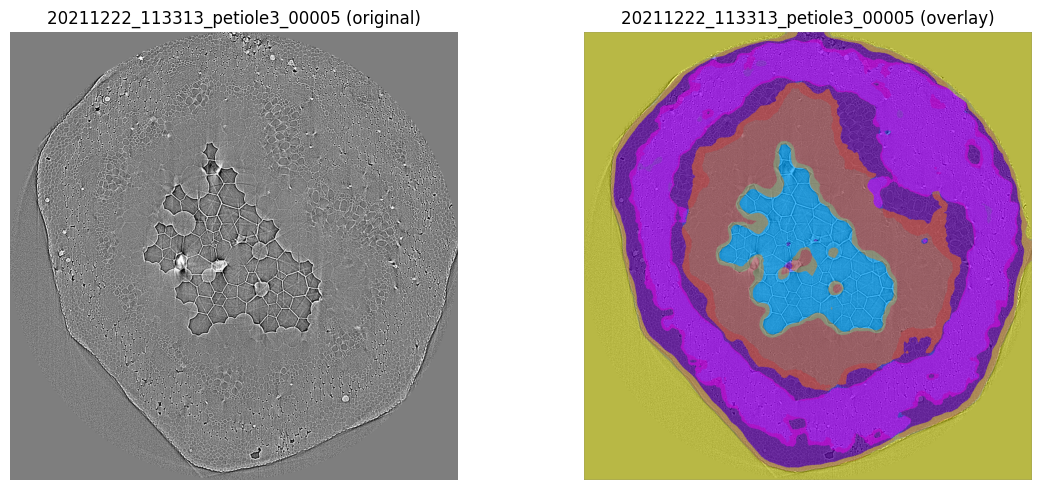

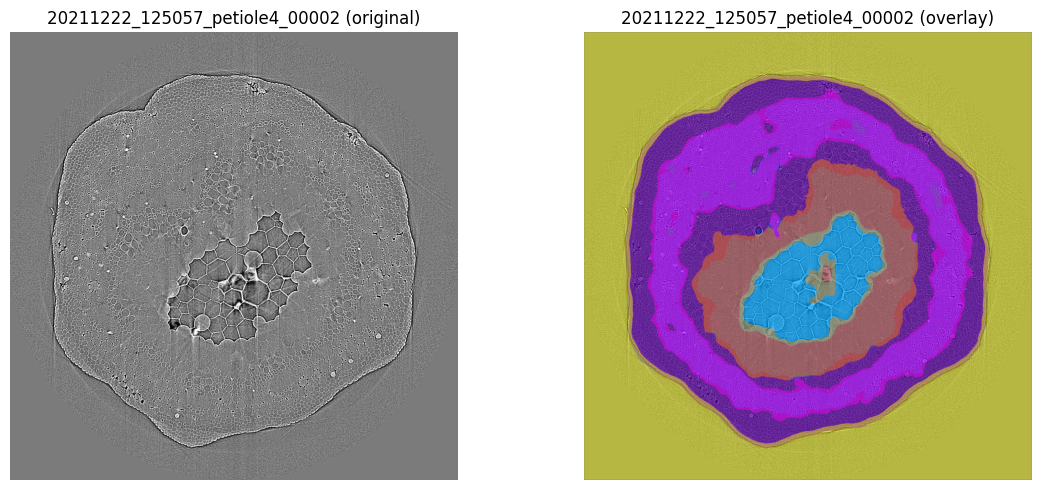

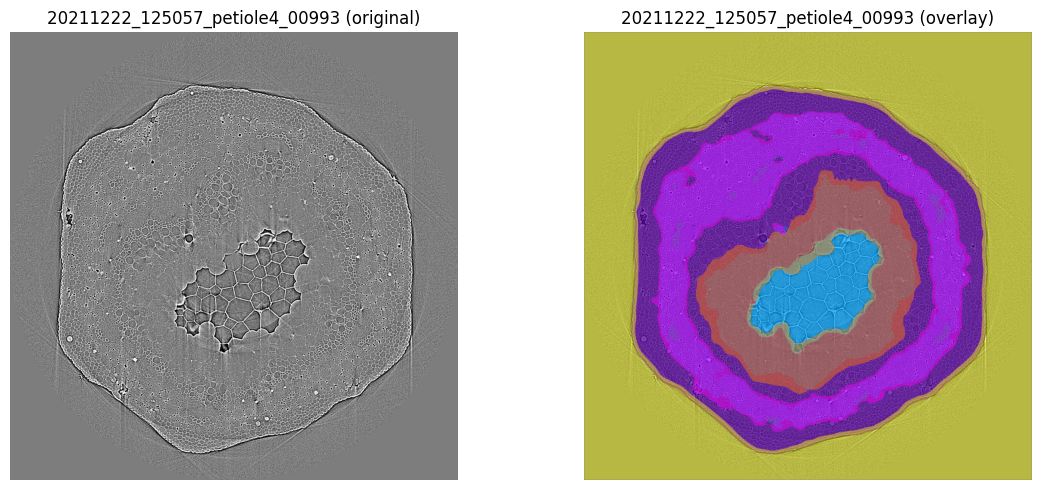

In [14]:
# =========================
# EXTRA CELL — Show 3 overlays (original + predicted masks)
# Assumes you already ran inference above and saved outputs to:
#   OUT_DIR/inference/originals/
#   OUT_DIR/inference/masks_per_class/<stem>/class_XX.png
# =========================
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
import cv2

OUT_DIR  = Path("/content/drive/MyDrive/petioles_models_multilabel/dinov3_seg")
INF_DIR  = OUT_DIR / "inference"
ORIG_DIR = INF_DIR / "originals"
MASK_DIR = INF_DIR / "masks_per_class"

assert ORIG_DIR.exists(), ORIG_DIR
assert MASK_DIR.exists(), MASK_DIR

# pick up to 3 images to visualize
orig_files = sorted(list(ORIG_DIR.glob("*.png")))
assert len(orig_files) > 0, f"No originals found in {ORIG_DIR}"

show_n = min(3, len(orig_files))
pick = orig_files[:show_n]  # you can random.sample(orig_files, show_n) if you want random

def overlay_masks_rgb(img_rgb_u8: np.ndarray, masks: np.ndarray, alpha=0.45):
    """
    img_rgb_u8: (H,W,3)
    masks: (C,H,W) bool or uint8 0/1
    Returns overlay RGB uint8
    """
    H, W = img_rgb_u8.shape[:2]
    out = img_rgb_u8.astype(np.float32).copy()

    # fixed colors for first few classes (extend if needed)
    colors = np.array([
        [255,   0,   0],   # red
        [  0, 255,   0],   # green
        [  0,   0, 255],   # blue
        [255, 255,   0],   # yellow
        [255,   0, 255],   # magenta
        [  0, 255, 255],   # cyan
        [255, 128,   0],   # orange
        [128,   0, 255],   # purple
    ], dtype=np.float32)

    C = masks.shape[0]
    for c in range(C):
        m = masks[c].astype(bool)
        if not m.any():
            continue
        col = colors[c % len(colors)]
        out[m] = (1 - alpha) * out[m] + alpha * col

    return np.clip(out, 0, 255).astype(np.uint8)

for f in pick:
    stem = f.stem
    img_bgr = cv2.imread(str(f), cv2.IMREAD_COLOR)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    per_img_dir = MASK_DIR / stem
    mask_files = sorted(list(per_img_dir.glob("class_*.png")))
    masks = []
    for mf in mask_files:
        m = cv2.imread(str(mf), cv2.IMREAD_GRAYSCALE)
        masks.append((m > 0).astype(np.uint8))
    masks = np.stack(masks, axis=0)

    overlay = overlay_masks_rgb(img_rgb, masks, alpha=0.45)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.title(stem + " (original)")
    plt.imshow(img_rgb)
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.title(stem + " (overlay)")
    plt.imshow(overlay)
    plt.axis("off")

    plt.tight_layout()
    plt.show()


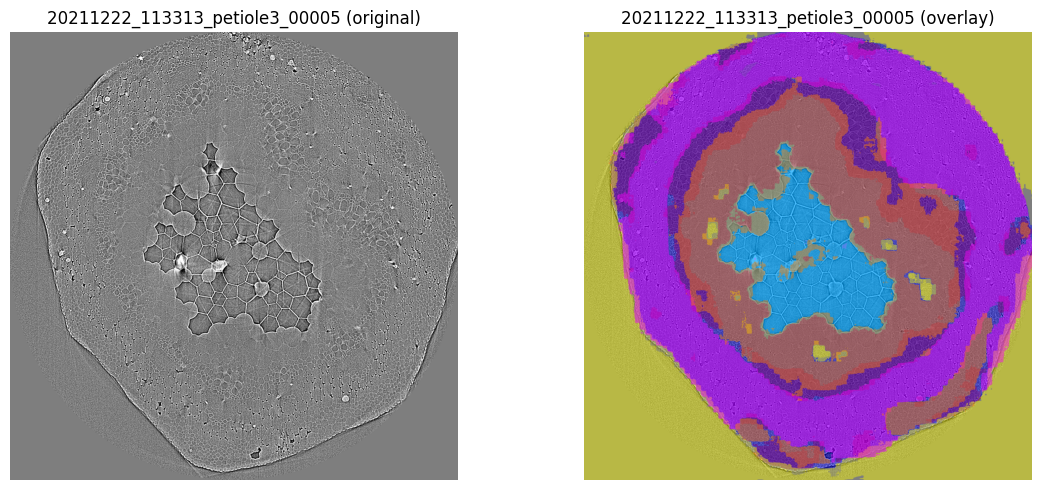

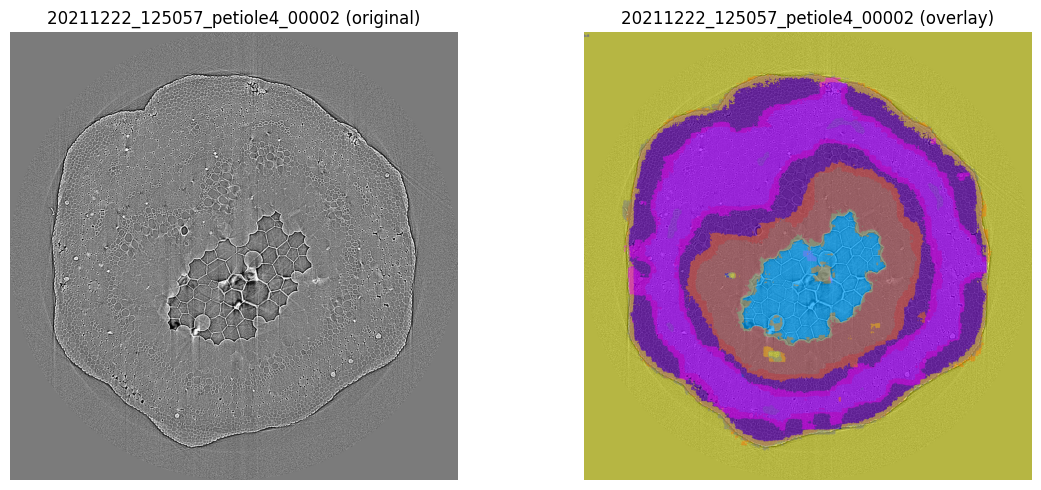

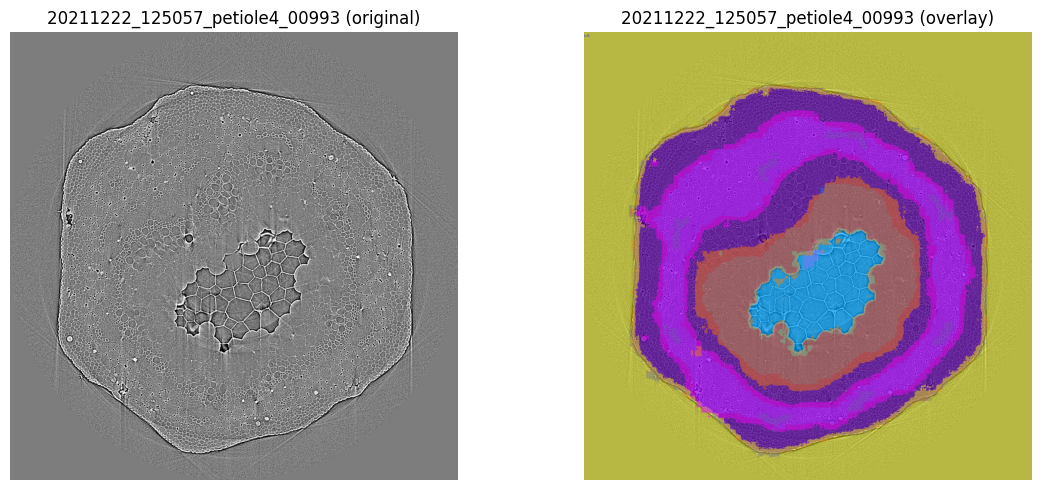

In [15]:
# =========================
# EXTRA CELL — Show 3 overlays (original + predicted masks)
# Assumes you already ran inference above and saved outputs to:
#   OUT_DIR/inference/originals/
#   OUT_DIR/inference/masks_per_class/<stem>/class_XX.png
# =========================
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
import cv2

OUT_DIR  = Path("/content/drive/MyDrive/petioles_models_multilabel/")
INF_DIR  = OUT_DIR / "inference_3d"
ORIG_DIR = INF_DIR / "originals"
MASK_DIR = INF_DIR / "masks_per_class"

assert ORIG_DIR.exists(), ORIG_DIR
assert MASK_DIR.exists(), MASK_DIR

# pick up to 3 images to visualize
orig_files = sorted(list(ORIG_DIR.glob("*.png")))
assert len(orig_files) > 0, f"No originals found in {ORIG_DIR}"

show_n = min(3, len(orig_files))
pick = orig_files[:show_n]  # you can random.sample(orig_files, show_n) if you want random

def overlay_masks_rgb(img_rgb_u8: np.ndarray, masks: np.ndarray, alpha=0.45):
    """
    img_rgb_u8: (H,W,3)
    masks: (C,H,W) bool or uint8 0/1
    Returns overlay RGB uint8
    """
    H, W = img_rgb_u8.shape[:2]
    out = img_rgb_u8.astype(np.float32).copy()

    # fixed colors for first few classes (extend if needed)
    colors = np.array([
        [255,   0,   0],   # red
        [  0, 255,   0],   # green
        [  0,   0, 255],   # blue
        [255, 255,   0],   # yellow
        [255,   0, 255],   # magenta
        [  0, 255, 255],   # cyan
        [255, 128,   0],   # orange
        [128,   0, 255],   # purple
    ], dtype=np.float32)

    C = masks.shape[0]
    for c in range(C):
        m = masks[c].astype(bool)
        if not m.any():
            continue
        col = colors[c % len(colors)]
        out[m] = (1 - alpha) * out[m] + alpha * col

    return np.clip(out, 0, 255).astype(np.uint8)

for f in pick:
    stem = f.stem
    img_bgr = cv2.imread(str(f), cv2.IMREAD_COLOR)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    per_img_dir = MASK_DIR / stem
    mask_files = sorted(list(per_img_dir.glob("class_*.png")))
    masks = []
    for mf in mask_files:
        m = cv2.imread(str(mf), cv2.IMREAD_GRAYSCALE)
        masks.append((m > 0).astype(np.uint8))
    masks = np.stack(masks, axis=0)

    overlay = overlay_masks_rgb(img_rgb, masks, alpha=0.45)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.title(stem + " (original)")
    plt.imshow(img_rgb)
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.title(stem + " (overlay)")
    plt.imshow(overlay)
    plt.axis("off")

    plt.tight_layout()
    plt.show()
